# Caracterización del Dataset Maestro SustainCrop

**Objetivo:** caracterizar la información del dataset (qué contiene, qué calidad tiene y cómo se distribuye) y definir **qué se debe hacer con él**.

Cada fila es una publicación científica (artículo, capítulo o conjunto de datos) con sus metadatos: DOI, año, revista, autores, instituciones, resumen, financiación y tres clasificaciones (relevancia, categoría SustainCrop y enfoque de sostenibilidad UE).

## Contenido del cuaderno
| Sección | Tema visto en clase | Qué se hace |
|---|---|---|
| 1 | Carga | Lectura del Excel y primer vistazo |
| 2 | **Limpieza** | Nombres, tipos, nulos, columnas inútiles, valores atípicos, normalización |
| 3 | **Medidas de tendencia central** | Media, mediana, moda y distribución de cada variable |
| 4 | **NLP y transformación vectorial** | Tokenización, frecuencia de palabras, TF-IDF, similitud y agrupamiento |
| 5 | Qué hacer con el dataset | Hallazgos y recomendaciones |

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Carga y primer vistazo

In [2]:
import re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

pd.set_option('display.max_colwidth', 80)
sns.set_theme(style='whitegrid', font_scale=0.95)

# Sube el Excel al panel de archivos de Colab (icono de carpeta, a la izquierda) y deja esta ruta.
RUTA = '/content/drive/MyDrive/Dataset_Maestro_SustainCrop.xlsx'

crudo = pd.read_excel(RUTA)
df = crudo.copy()          # copia de trabajo: 'crudo' queda intacto para comparar
print('Filas:', df.shape[0], '| Columnas:', df.shape[1])
df.head(3)

Filas: 63 | Columnas: 14


,DOI,HIPERVÍNCULO SINTETIZADO,AÑO,REVISTA,AUTORES,INSTITUCIONES_COLABORADORAS,TIPO DE CULTIVO,DATASET,RESUMEN DE ARTÍCULO,ENTE FINANCIADOR,CONVOCATORIA,RELEVANCIA,CATEGORÍA SUSTAINCROP,ENFOQUE SOSTENIBILIDAD UE
0,https://doi.org/10.5281/zenodo.19406165,https://doi.org/10.5281/zenodo.19406165,2026,Zenodo (CERN European Organization for Nuclear Research),Claudia Milena Serpa-Imbett; Lorena Aguayo-Ulloa; William Orlando Burgos-Paz...,"Universidad del Sinú, Universidad de Zaragoza, Corporación Colombiana de Inv...",NaN,Sí,"Multisensor, Multitemporal Forage Dataset: Megathyrsus maximus cv. Mombasa u...",NaN,NaN,Alta,Investigación & Conocimiento,agrosilvicultura
1,https://doi.org/10.29312/remexca.v17i6.4153,https://doi.org/10.29312/remexca.v17i6.4153,2026,Revista Mexicana de Ciencias Agrícolas,Laura Sánchez‐Castillo; Edmar Meléndez-Jaramillo; Marisol Delgado-González; ...,"Autonomous University of Tamaulipas, Universidad Autónoma de Nuevo León, Ins...",NaN,No,Soil is an essential and strategic resource for the sustainability of agricu...,NaN,NaN,Media,Investigación & Conocimiento,Agropastoral system
2,https://doi.org/10.1038/s41598-026-70051-1,https://doi.org/10.1038/s41598-026-70051-1,2026,Scientific Reports,Paola Vanessa Sierra Baquero; Filipa Monteiro; María Cristina Duarte; Maria ...,"University of Lisbon, Corporación Colombiana de Investigación Agropecuaria –...",NaN,No,Abstract Essential oils are increasingly recognized as ecofriendly alternati...,"Fundação para a Ciência e a Tecnologia, Ministério da Ciência, Tecnologia e ...",doi.org/10.54499/LA/P/0092/2020; UID/00329/2025; https://doi.org/10.54499/LA...,Alta,Investigación & Conocimiento,Gestión sostenible de plagas con aceites esenciales


In [3]:
resumen_cols = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    '% nulos': (df.isna().mean() * 100).round(1),
    'valores únicos': df.nunique(),
})
print('Filas duplicadas:', df.duplicated().sum())
print('DOI repetidos:', df['DOI'].duplicated().sum())
print('¿DOI == HIPERVÍNCULO en todas las filas?', (df['DOI'] == df['HIPERVÍNCULO SINTETIZADO']).all())
resumen_cols

Filas duplicadas: 0
DOI repetidos: 0
¿DOI == HIPERVÍNCULO en todas las filas? True


,tipo,nulos,% nulos,valores únicos
DOI,object,0,0.0,63
HIPERVÍNCULO SINTETIZADO,object,0,0.0,63
AÑO,int64,0,0.0,5
REVISTA,object,0,0.0,48
AUTORES,object,0,0.0,63
INSTITUCIONES_COLABORADORAS,object,0,0.0,41
TIPO DE CULTIVO,float64,63,100.0,0
DATASET,object,0,0.0,2
RESUMEN DE ARTÍCULO,object,0,0.0,63
ENTE FINANCIADOR,object,40,63.5,19


**Lectura:** el dataset tiene **63 filas y 14 columnas**, sin filas ni DOI duplicados. Dos problemas saltan a la vista:
- `TIPO DE CULTIVO` está **100 % vacía**.
- `HIPERVÍNCULO SINTETIZADO` es **idéntica** a `DOI`.

`ENTE FINANCIADOR` (63,5 % de nulos) y `CONVOCATORIA` (79,4 %) también tienen muchos vacíos, pero ahí un vacío probablemente significa «no reporta financiación», no un error.

## 2. Limpieza de datos
Se trabaja sobre la copia `df`; `crudo` queda intacto. Pasos: nombres de columna, columnas inútiles, tipos, nulos con significado, validación del DOI, conteos derivados, valores atípicos y normalización de categorías.

### 2.1 Nombres, columnas inútiles y tipos

In [4]:
# 1) Nombres de columna: sin tildes, minúsculas y con guion bajo
def limpiar_nombre(c):
    c = unicodedata.normalize('NFKD', c).encode('ascii', 'ignore').decode()
    return re.sub(r'\W+', '_', c.strip().lower()).strip('_')

df.columns = [limpiar_nombre(c) for c in df.columns]
df = df.rename(columns={'ano': 'anio'})     # 'AÑO' perdió la ñ al quitar tildes

# 2) Columnas que no aportan: tipo_de_cultivo (100 % vacía) e hipervinculo_sintetizado (copia exacta del DOI)
eliminadas = {}
for col, motivo in [('tipo_de_cultivo', '100 % de nulos'),
                    ('hipervinculo_sintetizado', 'idéntica a la columna DOI')]:
    eliminadas[col] = motivo
    df = df.drop(columns=col)
print('Columnas eliminadas:', eliminadas)

# 3) Texto: quitar espacios sobrantes en todas las columnas de texto
for c in df.select_dtypes(include=['object', 'string']).columns:
    df[c] = df[c].astype('string').str.strip()

# 4) Tipos: DATASET (Sí/No) a booleano y RELEVANCIA a categoría ordenada
df['es_dataset'] = df['dataset'].map({'Sí': True, 'No': False})
df['relevancia'] = pd.Categorical(df['relevancia'], categories=['Media', 'Alta'], ordered=True)
df = df.drop(columns='dataset')

# 5) Nulos con significado: "no reporta financiación" es información, no un error
df['tiene_financiador'] = df['ente_financiador'].notna()
df['tiene_convocatoria'] = df['convocatoria'].notna()

print('Columnas ahora:', list(df.columns))
df.dtypes

Columnas eliminadas: {'tipo_de_cultivo': '100 % de nulos', 'hipervinculo_sintetizado': 'idéntica a la columna DOI'}
Columnas ahora: ['doi', 'anio', 'revista', 'autores', 'instituciones_colaboradoras', 'resumen_de_articulo', 'ente_financiador', 'convocatoria', 'relevancia', 'categoria_sustaincrop', 'enfoque_sostenibilidad_ue', 'es_dataset', 'tiene_financiador', 'tiene_convocatoria']


,0
doi,string[python]
anio,int64
revista,string[python]
autores,string[python]
instituciones_colaboradoras,string[python]
resumen_de_articulo,string[python]
ente_financiador,string[python]
convocatoria,string[python]
relevancia,category
categoria_sustaincrop,string[python]


### 2.2 DOI: validación y editorial

In [5]:
# DOI: validar formato y extraer el prefijo (identifica a la editorial o repositorio)
df['doi_valido'] = df['doi'].str.match(r'^https?://doi\.org/10\.\d{4,9}/\S+$')
df['prefijo_doi'] = df['doi'].str.extract(r'doi\.org/(10\.\d+)')[0]
print('DOI con formato válido:', df['doi_valido'].sum(), 'de', len(df))

# ¿Qué revistas hay detrás de los prefijos más frecuentes? (sirve para ponerles nombre de editorial)
top_prefijos = df['prefijo_doi'].value_counts().head(6).index
(pd.crosstab(df.loc[df['prefijo_doi'].isin(top_prefijos), 'prefijo_doi'],
             df.loc[df['prefijo_doi'].isin(top_prefijos), 'revista'])
   .stack().loc[lambda s: s > 0].rename('artículos').reset_index().sort_values(['prefijo_doi', 'artículos'], ascending=[True, False])
   .groupby('prefijo_doi').head(3))

DOI con formato válido: 63 de 63


,prefijo_doi,revista,artículos
0,10.1016,Ecological Modelling,1
1,10.1016,Geoderma Regional,1
2,10.1016,Journal of Materials Research and Technology,1
6,10.18257,Revista de la Academia Colombiana de Ciencias Exactas Físicas y Naturales,3
7,10.21930,Corporación Colombiana de Investigación Agropecuaria (Agrosavia) eBooks,5
8,10.3389,Frontiers in Earth Science,1
9,10.3389,Frontiers in Environmental Science,1
10,10.3389,Frontiers in Plant Science,1
11,10.3390,Agriculture,2
12,10.3390,Applied Microbiology,1


In [ ]:
# Editorial/repositorio según el prefijo (solo los prefijos conocidos; el resto queda como 'Otra')
EDITORIAL = {'10.3390': 'MDPI', '10.1016': 'Elsevier', '10.3389': 'Frontiers', '10.1007': 'Springer',
             '10.1038': 'Nature', '10.5281': 'Zenodo', '10.1371': 'PLOS', '10.1002': 'Wiley', '10.1111': 'Wiley',
             '10.38141': 'Cenicafé', '10.21930': 'AGROSAVIA'}
df['editorial'] = df['prefijo_doi'].map(EDITORIAL).fillna('Otra')
print(df['editorial'].value_counts().to_string())

**Lectura:** los 63 DOI tienen formato válido. El prefijo permite identificar la editorial (por ejemplo `10.3390` = MDPI, `10.1016` = Elsevier); el resultado de la tabla anterior confirma que `10.38141` corresponde a revistas de Cenicafé y `10.21930` a publicaciones de AGROSAVIA. Los prefijos que no se reconocen quedan como «Otra».

### 2.3 Variables derivadas y valores atípicos

In [6]:
# Conteos a partir de listas: autores (separados por ';') e instituciones (separadas por ',')
df['n_autores'] = df['autores'].str.split(';').str.len()
df['n_instituciones'] = df['instituciones_colaboradoras'].str.split(',').str.len()

# Longitud del resumen
df['n_caracteres_resumen'] = df['resumen_de_articulo'].str.len()
df['n_palabras_resumen'] = df['resumen_de_articulo'].str.split().str.len()

df[['n_autores', 'n_instituciones', 'n_caracteres_resumen', 'n_palabras_resumen']].describe().round(1)

,n_autores,n_instituciones,n_caracteres_resumen,n_palabras_resumen
count,63.0,63.0,63.0,63.0
mean,4.5,2.2,1702.1,240.6
std,2.7,1.6,1079.7,146.3
min,1.0,1.0,307.0,50.0
25%,3.0,1.0,1377.0,193.0
50%,4.0,2.0,1531.0,230.0
75%,6.0,3.0,1838.0,250.5
max,14.0,9.0,9163.0,1236.0


In [7]:
# Valores atípicos del largo del resumen (regla del rango intercuartílico, IQR)
q1, q3 = df['n_palabras_resumen'].quantile([.25, .75])
limite = q3 + 1.5 * (q3 - q1)
atipicos = df[df['n_palabras_resumen'] > limite]
print(f'Límite superior: {limite:.0f} palabras | resúmenes por encima: {len(atipicos)}')
atipicos[['anio', 'revista', 'n_palabras_resumen']].assign(inicio=atipicos['resumen_de_articulo'].str[:70])

Límite superior: 337 palabras | resúmenes por encima: 5


,anio,revista,n_palabras_resumen,inicio
0,2026,Zenodo (CERN European Organization for Nuclear Research),1236,"Multisensor, Multitemporal Forage Dataset: Megathyrsus maximus cv. Mom"
12,2026,animal,393,Current methods used to measure methane ( CH 4 ) emissions from indivi
37,2026,Revista Argentina de Microbiología,496,• Azotobacter and Gluconacetobacter solubilize P from phosphate rock.
44,2019,Florida Entomologist,353,"Sugar cane stem borers, Diatraea spp. (Lepidoptera: Crambidae), are th"
55,2026,Journal of BioProcess and Chemical Technology (JBCT),382,"A nivel mundial se desechan millones de toneladas de alimentos, lo que"


**Lectura:** el largo del resumen tiene una cola muy larga: la mediana es de unas 230 palabras, pero hay un resumen de más de 1.200. Los 5 resúmenes atípicos incluyen descripciones de conjuntos de datos con secciones largas (por ejemplo, un «Overview» extenso). No se eliminan: son datos reales, pero conviene usar la **mediana** y no la media.

### 2.4 Normalización de instituciones

In [8]:
# Instituciones: ¿hay varios nombres para la misma entidad? Se agrupan con palabras clave
inst = (df['instituciones_colaboradoras'].str.split(',').explode().str.strip())
print('Nombres de institución distintos (sin normalizar):', inst.nunique())
print(inst.value_counts().head(8).to_string())

def institucion_canonica(nombre):
    n = nombre.lower()
    if 'agrosavia' in n or 'corporación colombiana de investigación agropecuaria' in n or 'colombian corporation for agricultural' in n:
        return 'AGROSAVIA'
    if 'centro nacional de investigaciones de café' in n or 'cenicafé' in n or 'cenicafe' in n:
        return 'Cenicafé'
    if 'caña de azúcar' in n or 'cenicaña' in n:
        return 'Cenicaña'
    return nombre

inst_norm = inst.map(institucion_canonica)
print('\nNombres distintos tras normalizar:', inst_norm.nunique())
print(inst_norm.value_counts().head(8).to_string())

Nombres de institución distintos (sin normalizar): 70
instituciones_colaboradoras
Corporación Colombiana de Investigación Agropecuaria – AGROSAVIA    18
Centro Nacional de Investigaciones de Café                          18
Centro de Investigación de la Caña de Azúcar de Colombia             9
Universidad de Antioquia                                             8
Universidad Nacional de Colombia                                     8
Universidad del Valle                                                6
Universidad de Caldas                                                3
Czech University of Life Sciences Prague                             2

Nombres distintos tras normalizar: 69
instituciones_colaboradoras
AGROSAVIA                                     20
Cenicafé                                      18
Cenicaña                                       9
Universidad Nacional de Colombia               8
Universidad de Antioquia                       8
Universidad del Valle                 

**Lectura:** la misma entidad aparece con nombres distintos (por ejemplo, AGROSAVIA en español y en inglés). Al unificar, AGROSAVIA pasa de 18 a 20 apariciones. Hay un problema adicional en `ente_financiador`: los nombres que llevan coma («Ministerio de Ciencia, Tecnología e Innovación») se parten mal si se separa por comas. Ese campo necesita otro delimitador (por ejemplo `;`) antes de poder contarse bien.

### 2.5 Enfoque de sostenibilidad UE: de 50 textos a pocos temas

In [9]:
# Enfoque de sostenibilidad UE: 50 textos distintos en 63 filas, mezclados en español e inglés.
# Se agrupan en temas con reglas de palabras clave (el orden importa: gana la primera regla que coincide).
REGLAS = [
    ('Diseño seguro y sostenible (SSbD)', ['ssbd', 'safe and sustainable']),
    ('Agroforestería y silvopastoreo',    ['agrosilvi', 'agroforest', 'silvopastoral', 'agropastoral', 'rotación de pasturas']),
    ('Agroecología y prácticas sostenibles', ['agroecol', 'prácticas agrícolas sostenibles', 'climate-smart', 'huertos']),
    ('Manejo de plagas y control biológico', ['plaga', 'pest', 'biocontrol', 'control biológico', 'bacterias lácticas', 'antibiosis',
                                              'parasitoides', 'mounding', 'pruning', 'polinizadores']),
    ('Fertilización y microorganismos',  ['fertiliz', 'biofertiliz', 'microorganismos', 'microrganismos', 'microbian', 'compostaje', 'urea', 'residuos de cultivos']),
    ('Secado y energía solar',           ['secado', 'solar', 'desiccant', 'drying', 'biomasa']),
    ('Agua y riego',                     ['riego', 'hídrico', 'sustratos', 'sin suelo', 'zonas de manejo']),
    ('Poscosecha, ganadería y subproductos', ['poscosecha', 'cosecha', 'ganado', 'metano', 'subproductos']),
]
def tema_enfoque(texto):
    t = str(texto).lower()
    for tema, claves in REGLAS:
        if any(k in t for k in claves):
            return tema
    return 'Otro'

df['tema_enfoque'] = df['enfoque_sostenibilidad_ue'].map(tema_enfoque)
print(df['tema_enfoque'].value_counts().to_string())
print('\nRevisar los que cayeron en "Otro":')
df.loc[df['tema_enfoque'] == 'Otro', 'enfoque_sostenibilidad_ue'].tolist()

tema_enfoque
Manejo de plagas y control biológico    13
Diseño seguro y sostenible (SSbD)       13
Agroecología y prácticas sostenibles     9
Agroforestería y silvopastoreo           8
Fertilización y microorganismos          8
Poscosecha, ganadería y subproductos     4
Agua y riego                             4
Secado y energía solar                   4

Revisar los que cayeron en "Otro":


[]

**Lectura:** `enfoque_sostenibilidad_ue` tenía 50 textos distintos en 63 filas, mezclando español e inglés («agroforestry», «agrosilvicultura», «Agroforestería»). Con reglas de palabras clave quedan **8 temas**; los dos más frecuentes son *manejo de plagas y control biológico* y *Safe and Sustainable by Design (SSbD)*, con 13 artículos cada uno. Las reglas son un primer borrador y conviene revisarlas con el equipo.

### 2.6 Idioma del resumen y cultivo (columna vacía)

In [10]:
# Idioma del resumen: se cuentan palabras vacías típicas de cada idioma (sin librerías externas)
VACIAS_ES = set('de la el en y que los las del se por con para una un es al como más su lo sus entre este esta fue son ha sobre también'.split())
VACIAS_EN = set('the of and in to is a for with that on as by was were this are be from at an or which has it its their been'.split())

def detectar_idioma(texto):
    palabras = re.findall(r'[a-záéíóúñ]+', texto.lower())
    es, en = sum(p in VACIAS_ES for p in palabras), sum(p in VACIAS_EN for p in palabras)
    return 'es' if es > en else 'en'

df['idioma'] = df['resumen_de_articulo'].map(detectar_idioma)
print(df['idioma'].value_counts().to_string())

idioma
en    41
es    22


In [11]:
# El campo tipo_de_cultivo vino vacío. ¿Se puede reconstruir a partir del resumen? Prueba con palabras clave.
CULTIVOS = {
    'Café':               r'\b(coffee|café|cafeto)\b',
    'Caña de azúcar':     r'\b(sugarcane|sugar cane|caña de azúcar)\b',
    'Yuca':               r'\b(cassava|yuca)\b',
    'Pastos y forrajes':  r'\b(forage|forraje|pasture|pastura|pasto|pastos|megathyrsus|silvopastoral)\b',
    'Maíz':               r'\b(maize|maíz|corn)\b',
    'Cacao':              r'\b(cacao|cocoa)\b',
    'Banano y plátano':   r'\b(banana|banano|plantain|plátano)\b',
    'Papa':               r'\b(potato|potatoes|papa)\b',
    'Aguacate':           r'\b(avocado|aguacate)\b',
    'Hortalizas':         r'\b(vegetable|vegetables|hortaliza|hortalizas|lettuce|lechuga|tomato|tomate)\b',
    'Arroz':              r'\b(rice|arroz)\b',
}
def detectar_cultivos(texto):
    t = texto.lower()          # \b marca límite de palabra: evita que "rice" coincida con "price"
    return [c for c, patron in CULTIVOS.items() if re.search(patron, t)]

df['cultivos_detectados'] = df['resumen_de_articulo'].map(detectar_cultivos)
con_cultivo = df['cultivos_detectados'].str.len() > 0
print(f'Resúmenes con al menos un cultivo detectado: {con_cultivo.sum()} de {len(df)} ({con_cultivo.mean()*100:.0f} %)')
print(df['cultivos_detectados'].explode().value_counts().to_string())

Resúmenes con al menos un cultivo detectado: 40 de 63 (63 %)
cultivos_detectados
Café                 21
Caña de azúcar        7
Arroz                 4
Pastos y forrajes     3
Hortalizas            3
Maíz                  3
Banano y plátano      2
Papa                  1
Yuca                  1


**Lectura:** 41 resúmenes están en inglés y 22 en español. Como `tipo_de_cultivo` vino vacía, se probó reconstruirla con palabras clave sobre el resumen: se detecta al menos un cultivo en **40 de 63 resúmenes (63 %)**, con el café como el más frecuente. Es una aproximación (no distingue si el cultivo es el tema central o solo se menciona), pero muestra que la columna se puede recuperar en buena parte.

## 3. Medidas de tendencia central
Para cada variable numérica: **media, mediana, moda**, desviación estándar y asimetría. Si la media y la mediana se separan mucho, la variable es asimétrica y la mediana es mejor resumen.

In [12]:
# Medidas de tendencia central para las variables numéricas
numericas = ['anio', 'n_autores', 'n_instituciones', 'n_palabras_resumen']

def tendencia(s):
    moda = s.mode()
    return pd.Series({'media': s.mean(), 'mediana': s.median(),
                      'moda': moda.iloc[0] if len(moda) else np.nan,
                      'desv. estándar': s.std(), 'mín': s.min(), 'máx': s.max(),
                      'asimetría': s.skew()})

tabla_central = df[numericas].apply(tendencia).T.round(2)
tabla_central

,media,mediana,moda,desv. estándar,mín,máx,asimetría
anio,2025.49,2026.0,2026.0,1.16,2019.0,2026.0,-3.80
n_autores,4.51,4.0,3.0,2.74,1.0,14.0,1.38
n_instituciones,2.21,2.0,1.0,1.59,1.0,9.0,1.97
n_palabras_resumen,240.57,230.0,156.0,146.26,50.0,1236.0,5.25


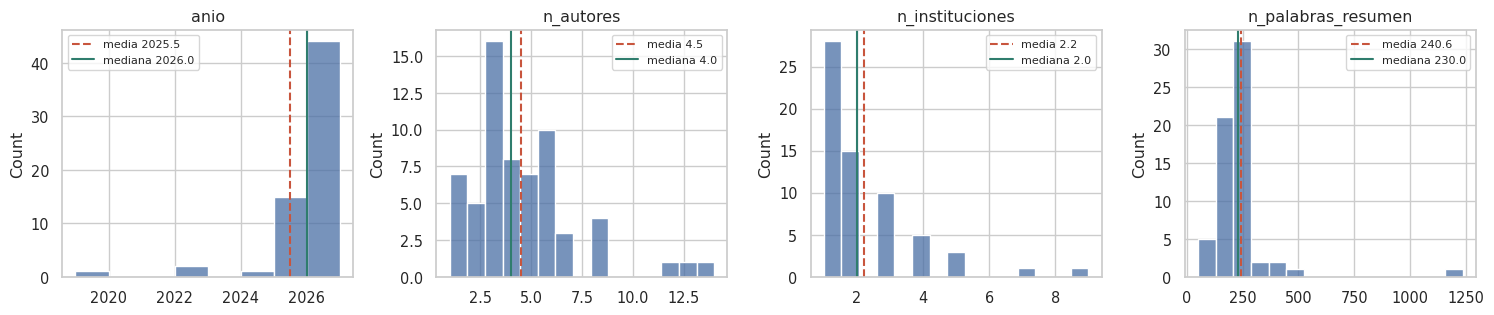

In [13]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.3))
for ax, col in zip(axs, numericas):
    sns.histplot(df[col], bins=15 if col != 'anio' else range(2019, 2028), color='#4a6fa5', ax=ax)
    ax.axvline(df[col].mean(), color='#c8553d', ls='--', label=f'media {df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='#2f7d6d', ls='-', label=f'mediana {df[col].median():.1f}')
    ax.set_title(col); ax.set_xlabel(''); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura:**
- **Año:** media 2025,5, mediana y moda 2026. La asimetría es muy negativa (−3,8): casi todo el dataset es reciente.
- **Autores:** mediana 4 y moda 3; media 4,5. Pocos artículos con muchos autores (máximo 14) alargan la cola.
- **Instituciones:** mediana 2 y moda 1: lo típico es una o dos instituciones por publicación.
- **Palabras del resumen:** media 241 y mediana 230, con asimetría alta (5,3) por los resúmenes atípicos. La moda de una variable continua como esta no es informativa.

In [16]:
# Medias y medianas por grupo: ¿cambian según sea dataset o no, y según la relevancia?
for grupo in ['es_dataset', 'relevancia']:
    print(f'\n--- por {grupo} ---')
    display(df.groupby(grupo, observed=True)[['n_autores', 'n_instituciones', 'n_palabras_resumen']]
              .agg(['mean', 'median']).round(1))

print('\nFinanciación según sea dataset (% con financiador reportado):')
print((df.groupby('es_dataset')['tiene_financiador'].mean() * 100).round(1).to_string())


--- por es_dataset ---


n_autores        n_instituciones        n_palabras_resumen       
                mean median            mean median               mean median
es_dataset                                                                  
False            4.4    4.0             1.8    1.0              208.1  211.0
True             4.6    4.0             2.8    2.0              283.9  238.0


--- por relevancia ---


n_autores        n_instituciones        n_palabras_resumen       
                mean median            mean median               mean median
relevancia                                                                  
Media            5.1    3.5             2.3    2.0              201.8  213.0
Alta             4.3    4.0             2.2    2.0              253.8  231.0


Financiación según sea dataset (% con financiador reportado):
es_dataset
False    22.2
True     55.6


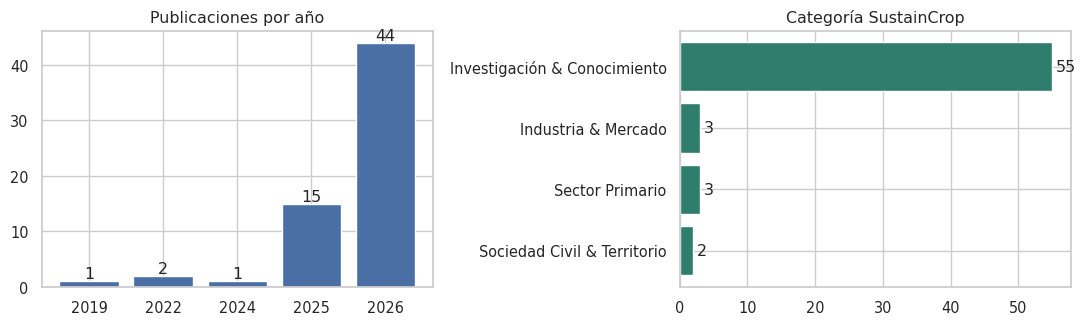

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
orden = df['anio'].value_counts().sort_index()
axs[0].bar(orden.index.astype(str), orden.values, color='#4a6fa5')
for i, v in enumerate(orden.values): axs[0].text(i, v + .5, v, ha='center')
axs[0].set_title('Publicaciones por año')
cat = df['categoria_sustaincrop'].value_counts()
axs[1].barh(cat.index, cat.values, color='#2f7d6d'); axs[1].invert_yaxis()
for i, v in enumerate(cat.values): axs[1].text(v + .5, i, v, va='center')
axs[1].set_title('Categoría SustainCrop')
plt.tight_layout(); plt.show()

**Lectura:**
- La **moda** de la mayoría de variables categóricas es muy dominante: 2026 (70 %), relevancia *Alta* (75 %) y categoría *Investigación & Conocimiento* (87 %).
- Las otras tres categorías SustainCrop (Industria & Mercado, Sector Primario, Sociedad Civil & Territorio) suman solo 8 artículos.
- Los artículos que son conjuntos de datos (`es_dataset = Sí`, 27 de 63) tienen en promedio más instituciones (2,8 frente a 1,8) y reportan financiador con más frecuencia (56 % frente a 22 %).

## 4. Procesamiento de lenguaje natural y transformación vectorial
Se trabaja con la columna `resumen_de_articulo`. Pasos: (1) limpiar y tokenizar el texto, (2) contar palabras, (3) convertir cada resumen en un **vector** (bolsa de palabras y TF-IDF), (4) medir similitud entre resúmenes y (5) agrupar.

**TF-IDF** da más peso a las palabras que aparecen mucho en un resumen pero en pocos resúmenes, así que resalta lo que distingue a cada documento.

### 4.1 Limpieza y tokenización del texto

In [18]:
# Preparación del texto: minúsculas, sin tildes, solo letras, sin palabras vacías
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def sin_tildes(t):
    return unicodedata.normalize('NFKD', t).encode('ascii', 'ignore').decode()

# Palabras vacías: si NLTK está disponible se usa su lista (español + inglés); si no, las listas básicas de arriba
try:
    import nltk
    nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords
    VACIAS = set(stopwords.words('spanish')) | set(stopwords.words('english'))
    print('Palabras vacías: NLTK')
except Exception:
    VACIAS = set(VACIAS_ES) | set(ENGLISH_STOP_WORDS) | VACIAS_EN
    print('Palabras vacías: listas básicas (NLTK no disponible)')
VACIAS = {sin_tildes(p) for p in VACIAS}

# Palabras que aparecen en casi todos los resúmenes científicos y no distinguen un artículo de otro
RUIDO = set('abstract overview study studies results result using used use based dataset data paper article research analysis '
            'estudio resultados datos articulo investigacion analisis mediante entre sobre'.split())

def limpiar_texto(t):
    t = sin_tildes(t.lower())
    t = re.sub(r'https?://\S+|\d+', ' ', t)
    return [p for p in re.findall(r'[a-z]{3,}', t) if p not in VACIAS and p not in RUIDO]

df['tokens'] = df['resumen_de_articulo'].map(limpiar_texto)
df['texto_limpio'] = df['tokens'].str.join(' ')
print('Tokens por resumen (mediana):', int(df['tokens'].str.len().median()))
print('Ejemplo:', df['tokens'].iloc[0][:15])

Palabras vacías: NLTK
Tokens por resumen (mediana): 131
Ejemplo: ['multisensor', 'multitemporal', 'forage', 'megathyrsus', 'maximus', 'mombasa', 'tropical', 'silvopastoral', 'conditions', 'wet', 'dry', 'seasons', 'colombian', 'caribbean', 'comprises']


*Nota:* si NLTK está disponible (en Colab suele estarlo), el cuaderno usa su lista de palabras vacías en español e inglés; si no, usa las listas básicas definidas arriba.

### 4.2 Frecuencia de palabras

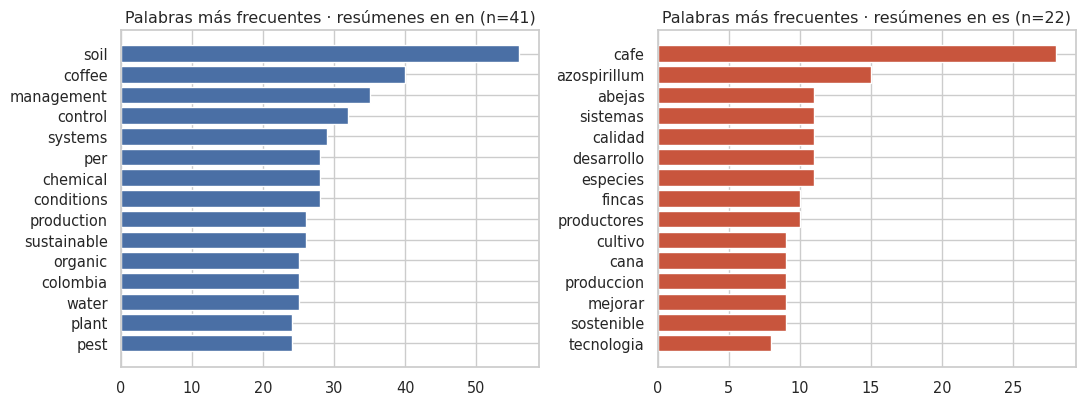

In [19]:
# Frecuencia de palabras: global y por idioma
def top_palabras(tokens_series, n=15):
    return pd.Series(Counter(t for toks in tokens_series for t in toks)).sort_values(ascending=False).head(n)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, idioma, color in zip(axs, ['en', 'es'], ['#4a6fa5', '#c8553d']):
    top = top_palabras(df.loc[df['idioma'] == idioma, 'tokens'])
    ax.barh(top.index, top.values, color=color); ax.invert_yaxis()
    ax.set_title(f'Palabras más frecuentes · resúmenes en {idioma} (n={(df.idioma == idioma).sum()})')
plt.tight_layout(); plt.show()

### 4.3 Vectorización: bolsa de palabras y TF-IDF

In [20]:
# Vectorización 1: bolsa de palabras (CountVectorizer) y TF-IDF, con unigramas y bigramas
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

conteo = CountVectorizer(ngram_range=(1, 2), min_df=2)
X_conteo = conteo.fit_transform(df['texto_limpio'])

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X = tfidf.fit_transform(df['texto_limpio'])
terminos = np.array(tfidf.get_feature_names_out())

print('Matriz de conteo :', X_conteo.shape)
print('Matriz TF-IDF    :', X.shape, '(documentos x términos)')
print(f'Proporción de ceros (matriz dispersa): {(1 - X.nnz / (X.shape[0] * X.shape[1])) * 100:.1f} %')

# Los 15 términos con mayor peso TF-IDF promedio
pesos = pd.Series(np.asarray(X.mean(axis=0)).ravel(), index=terminos).sort_values(ascending=False)
pesos.head(15).round(3)

Matriz de conteo : (63, 1378)
Matriz TF-IDF    : (63, 1378) (documentos x términos)
Proporción de ceros (matriz dispersa): 94.8 %


,0
soil,0.029
cafe,0.028
coffee,0.028
control,0.026
colombia,0.024
management,0.022
chemical,0.022
water,0.021
plant,0.021
production,0.021


**Lectura:** cada resumen se convierte en un vector de 1.355 términos (unigramas y bigramas que aparecen en al menos 2 resúmenes). La matriz es **dispersa**: cerca del 95 % son ceros, algo normal en texto. Los términos con más peso promedio (*soil*, *coffee*, *café*, *control*, *management*) muestran que el dataset gira alrededor de suelos, café y manejo de cultivos.

In [21]:
# ¿Qué términos distinguen a cada grupo? Se promedian los vectores TF-IDF dentro del grupo
def terminos_distintivos(mascara, n=8):
    media = np.asarray(X[mascara.values].mean(axis=0)).ravel()
    return ', '.join(terminos[np.argsort(media)[::-1][:n]])

for etiqueta, mascara in [('Es dataset (Sí)', df['es_dataset']), ('No es dataset', ~df['es_dataset']),
                          ('Relevancia Alta', df['relevancia'] == 'Alta'), ('Relevancia Media', df['relevancia'] == 'Media'),
                          ('Resumen en inglés', df['idioma'] == 'en'), ('Resumen en español', df['idioma'] == 'es')]:
    print(f'{etiqueta:20s} → {terminos_distintivos(mascara)}')

Es dataset (Sí)      → water, high, soil, conditions, showed, organic, values, potential
No es dataset        → cafe, coffee, control, productores, sistemas, desarrollo, calidad, sostenible
Relevancia Alta      → coffee, control, cafe, chemical, management, soil, plant, evaluated
Relevancia Media     → abejas, soil, colombia, fincas, secado, solar, especies, agricultural
Resumen en inglés    → soil, coffee, management, control, chemical, water, systems, sustainable
Resumen en español   → cafe, productores, calidad, sistemas, desarrollo, sostenible, secado, cultivo


### 4.4 Similitud entre resúmenes

In [22]:
# Similitud del coseno entre resúmenes: ¿qué artículos hablan de lo mismo?
from sklearn.metrics.pairwise import cosine_similarity

S = cosine_similarity(X)
np.fill_diagonal(S, 0)
i, j = np.triu_indices_from(S, k=1)
pares = pd.DataFrame({'a': i, 'b': j, 'similitud': S[i, j]}).sort_values('similitud', ascending=False).head(5)
for _, p in pares.iterrows():
    print(f"similitud {p.similitud:.2f}")
    print('   A:', df['resumen_de_articulo'].iloc[int(p.a)][:110].replace('\n', ' '))
    print('   B:', df['resumen_de_articulo'].iloc[int(p.b)][:110].replace('\n', ' '))
print(f'\nSimilitud promedio entre pares distintos: {S[i, j].mean():.3f}')
print('Similitud promedio entre resúmenes del mismo idioma vs. de distinto idioma:')
mismo = (df['idioma'].values[i] == df['idioma'].values[j])
print(f'   mismo idioma: {S[i, j][mismo].mean():.3f} | distinto idioma: {S[i, j][~mismo].mean():.3f}')

similitud 0.38
   A: Los empaques plásticos convencionales generan contaminación y los biodegradables actuales actúan solo como bar
   B: A nivel mundial se desechan millones de toneladas de alimentos, lo que representa un problema de interés globa
similitud 0.36
   A: Management of sugarcane stem borers (Diatraea spp.) in Colombia's Cauca River Valley (CRV) relies mainly on bi
   B: Sugar cane stem borers, Diatraea spp. (Lepidoptera: Crambidae), are the most important pests affecting sugar c
similitud 0.33
   A: Coffee drying in humid regions is frequently hindered by high rainfall and elevated relative humidity during p
   B: ABSTRACT Solar drying is the most common method for drying parchment coffee on smallholder farms due to its lo
similitud 0.32
   A: El bosque seco tropical del Valle del Cauca en Colombia es uno de los biomas más transformados por la expansió
   B: Aunque el café en Colombia es una especie predominantemente autógama, la polinización por abejas optimiza su p
simi

**Lectura:** la similitud promedio entre pares es muy baja (≈ 0,04), lo que indica temas dispersos. Los pares más parecidos sí tienen sentido (por ejemplo, dos artículos sobre barrenadores de la caña de azúcar y dos sobre secado de café). Lo más importante: la similitud entre resúmenes del **mismo idioma** es mucho mayor que entre idiomas distintos, porque TF-IDF compara palabras literales y no entiende que *coffee* y *café* son lo mismo.

### 4.5 Agrupamiento (KMeans)

In [23]:
# Agrupamiento (KMeans) sobre los vectores TF-IDF. Se elige k con el coeficiente de silueta.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD

silueta = {}
for k in range(2, 8):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    silueta[k] = silhouette_score(X, etiquetas)
print({k: round(v, 3) for k, v in silueta.items()})
k_mejor = max(silueta, key=silueta.get)
print('k elegido:', k_mejor)

df['grupo'] = KMeans(n_clusters=k_mejor, n_init=10, random_state=42).fit_predict(X)
print('\nGrupo × idioma:'); print(pd.crosstab(df['grupo'], df['idioma']))
print('\nTérminos principales de cada grupo:')
for g in sorted(df['grupo'].unique()):
    print(f'  Grupo {g} (n={(df.grupo == g).sum()}): {terminos_distintivos(df["grupo"] == g)}')

{2: np.float64(0.037), 3: np.float64(0.018), 4: np.float64(0.012), 5: np.float64(0.015), 6: np.float64(0.013), 7: np.float64(0.018)}
k elegido: 2

Grupo × idioma:
idioma  en  es
grupo         
0       41   1
1        0  21

Términos principales de cada grupo:
  Grupo 0 (n=42): soil, coffee, management, chemical, control, water, plant, production
  Grupo 1 (n=21): cafe, productores, calidad, sistemas, desarrollo, sostenible, secado, fincas


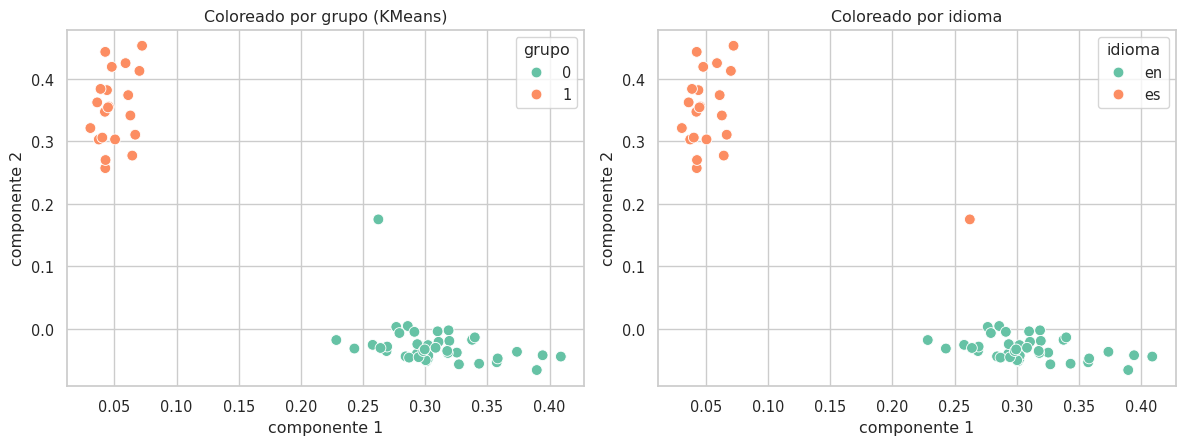

In [24]:
# Mapa en 2 dimensiones (SVD): cada punto es un resumen
XY = TruncatedSVD(n_components=2, random_state=42).fit_transform(X)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, col, titulo in [(axs[0], 'grupo', 'Coloreado por grupo (KMeans)'), (axs[1], 'idioma', 'Coloreado por idioma')]:
    sns.scatterplot(x=XY[:, 0], y=XY[:, 1], hue=df[col].astype(str), palette='Set2', s=60, ax=ax)
    ax.set_title(titulo); ax.set_xlabel('componente 1'); ax.set_ylabel('componente 2')
plt.tight_layout(); plt.show()

**Lectura:** el mejor agrupamiento con k = 2 separa **por idioma** (41 en inglés frente a 21–22 en español), no por tema, y su coeficiente de silueta es muy bajo (≈ 0,04). Es decir, el idioma domina el espacio vectorial y tapa la estructura temática. Para ver temas, se repite el agrupamiento solo con los resúmenes en inglés.

In [25]:
# El primer agrupamiento solo separó idiomas. Para ver temas, se agrupan solo los resúmenes en inglés (n = 41)
en = df['idioma'] == 'en'
X_en = X[en.values]
sil_en = {}
for k in range(2, 7):
    sil_en[k] = silhouette_score(X_en, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_en))
print('Silueta (solo inglés):', {k: round(v, 3) for k, v in sil_en.items()})
k_en = max(sil_en, key=sil_en.get)

df.loc[en, 'grupo_en'] = KMeans(n_clusters=k_en, n_init=10, random_state=42).fit_predict(X_en)
print('k elegido:', k_en)
for g in sorted(df['grupo_en'].dropna().unique()):
    m = (df['grupo_en'] == g)
    print(f'\n  Grupo {int(g)} (n={m.sum()}): {terminos_distintivos(m)}')
    print('     temas de enfoque:', df.loc[m, 'tema_enfoque'].value_counts().head(3).to_dict())

Silueta (solo inglés): {2: np.float64(0.01), 3: np.float64(0.011), 4: np.float64(0.012), 5: np.float64(0.012), 6: np.float64(0.017)}
k elegido: 6

  Grupo 0 (n=4): plant, revealed, coffee, sustainable, applications, potential, derived, structural
     temas de enfoque: {'Fertilización y microorganismos': 2, 'Manejo de plagas y control biológico': 1, 'Diseño seguro y sostenible (SSbD)': 1}

  Grupo 1 (n=9): conditions, growth, treatments, production, control, evaluated, plant, performance
     temas de enfoque: {'Fertilización y microorganismos': 3, 'Poscosecha, ganadería y subproductos': 2, 'Manejo de plagas y control biológico': 2}

  Grupo 2 (n=7): pest, control, biological, larvae, coffee, larval, releases, insecticides
     temas de enfoque: {'Manejo de plagas y control biológico': 6, 'Diseño seguro y sostenible (SSbD)': 1}

  Grupo 3 (n=5): coffee, drying, quality, humidity, environmental, times, morphological, showed
     temas de enfoque: {'Secado y energía solar': 2, 'Agrofores

**Lectura:** incluso dentro del inglés la silueta es muy baja (≈ 0,01), así que la estructura temática es **débil**: con solo 41 resúmenes y temas muy variados no hay grupos nítidos. Aun así, algunos grupos son interpretables: uno sobre control de plagas y liberaciones de insectos, otro sobre secado de café, otro sobre suelos y sistemas agroecológicos y otro sobre extracción y biochar, asociado al tema SSbD. Estos grupos sirven como **pista exploratoria**, no como clasificación definitiva.

## 5. ¿Qué se debe hacer con este dataset?

### 5.1 Hallazgos
| Aspecto | Hallazgo |
|---|---|
| Tamaño | 63 publicaciones: sirve para describir, es **muy pequeño** para modelos supervisados |
| Calidad | `tipo_de_cultivo` vacía; `hipervinculo_sintetizado` duplicada; DOI todos válidos y sin repetidos |
| Cobertura temporal | 70 % es de 2026 y 94 % de 2025–2026: es una **foto reciente**, no una serie histórica |
| Cobertura temática | 87 % es *Investigación & Conocimiento*; las otras 3 categorías suman 8 artículos |
| Consistencia | Enfoque con 50 textos (español e inglés mezclados); instituciones con nombres repetidos; financiadores con delimitador ambiguo |
| Idioma | 65 % en inglés y 35 % en español; el idioma domina cualquier análisis vectorial |
| Financiación | 63,5 % sin financiador y 79,4 % sin convocatoria |

### 5.2 Recomendaciones (en orden de prioridad)
1. **Corregir la estructura:** eliminar `hipervinculo_sintetizado` (copia del DOI) y decidir qué hacer con `tipo_de_cultivo`: llenarla (la detección automática ya cubre el 63 %) o quitarla.
2. **Normalizar categorías:** adoptar un catálogo único para el enfoque de sostenibilidad (los 8 temas de este cuaderno son un punto de partida), unificar nombres de instituciones y separar los financiadores con `;`.
3. **Resolver el problema del idioma** antes de hacer minería de texto seria: traducir los resúmenes a un solo idioma o usar embeddings multilingües (por ejemplo, un modelo de `sentence-transformers`) en lugar de TF-IDF.
4. **Documentar el significado de los vacíos:** si «sin financiador» significa «no reporta», marcarlo así; si significa «no se buscó», completarlo.
5. **Ampliar la muestra** si el propósito es analizar todo el ecosistema (industria, sector primario, sociedad civil) o entrenar modelos: hoy hay muy poca cobertura de esas categorías y casi todo es de 2025–2026.
6. **Definir el criterio de `relevancia` y `categoría_sustaincrop`:** hoy no se sabe cómo se asignaron; conviene documentarlo para que otros puedan replicarlo.

### 5.3 Usos posibles tal como está
- **Catálogo consultable** de literatura sobre agricultura sostenible en Colombia (con filtros por tema, institución y cultivo).
- **Mapa de actores:** qué instituciones publican y con quién colaboran (AGROSAVIA, Cenicafé y Cenicaña aparecen como las más frecuentes).
- **Vigilancia de la literatura:** base para ir sumando artículos nuevos con el mismo formato.

### 5.4 Limitaciones de este análisis
- Las reglas de temas, de cultivos y de instituciones son **heurísticas** hechas a mano; hay que revisarlas.
- La detección de idioma usa listas cortas de palabras vacías; funciona bien con resúmenes largos, pero no se validó con una librería externa.
- Con 63 documentos, los resultados de similitud y agrupamiento son **exploratorios**, y la silueta baja indica que los grupos no son nítidos.
- No se conoce el procedimiento con que se construyó el dataset, por lo que no se puede evaluar su sesgo de selección.